In [2]:
import pandas as pd
from pathlib import Path

import load_data

In [3]:
hl_hype = load_data.get_md(
    'HYPERLIQUID',
    'HYPE-USD-PERP',
    'book')
    
bin_hype = load_data.get_md(
    'BINANCE_FUTURES',
    'HYPE-USDT-PERP',
    'book')

In [4]:
hl_hype.head()

,exchange,symbol,bid,bid_size,ask,ask_size,mid,spread,spread_bps,imbalance,microprice,exchange_timestamp,receipt_timestamp
datetime,,,,,,,,,,,,,
2026-09-29 03:16:28.325776815+00:00,HYPERLIQUID,HYPE-USD-PERP,86.246,173.24,86.247,0.57,86.2465,0.001,0.115947,0.993441,86.246997,1.790652e+09,1.790652e+09
2026-09-29 03:16:32.450516462+00:00,HYPERLIQUID,HYPE-USD-PERP,86.209,5.50,86.210,596.12,86.2095,0.001,0.115996,-0.981716,86.209009,1.790652e+09,1.790652e+09
2026-09-29 03:16:37.890242815+00:00,HYPERLIQUID,HYPE-USD-PERP,86.227,4.64,86.228,4.64,86.2275,0.001,0.115972,0.000000,86.227500,1.790652e+09,1.790652e+09
2026-09-29 03:16:43.358217478+00:00,HYPERLIQUID,HYPE-USD-PERP,86.252,20.99,86.254,34.78,86.2530,0.002,0.231876,-0.247266,86.252753,1.790652e+09,1.790652e+09
2026-09-29 03:16:48.682182550+00:00,HYPERLIQUID,HYPE-USD-PERP,86.272,419.33,86.273,1.42,86.2725,0.001,0.115912,0.993250,86.272997,1.790652e+09,1.790652e+09


In [5]:
b_1min = (
    bin_hype[["mid", "bid", 'ask', 'bid_size', 'ask_size', 'imbalance', 'microprice']]
    .resample("60000ms")
    .last()
    .ffill()
    .rename(columns={"mid": "bin_mid", "bid": "bin_bid", 
                    'bid_size':'bid_size_bin', 'ask_size':'ask_size_bin',
                    'imbalance':'imbalance_bin', 'microprice':'microprice_bin'})
)

h_1min = (
    hl_hype[["mid", "bid", 'bid_size', 'ask_size', 'imbalance', 'microprice']]
    .resample("60000ms")
    .last()
    .ffill()
    .rename(columns={"mid": "hl_mid", "bid": "hl_bid",
                    'bid_size':'bid_size_hl', 'ask_size':'ask_size_hl',
                    'imbalance':'imbalance_hl', 'microprice':'microprice_hl'})
)

# Merge them on their timestamp indexes
df = b_1min.join(h_1min, how="inner")
df.tail()

,bin_mid,bin_bid,ask,bid_size_bin,ask_size_bin,imbalance_bin,microprice_bin,hl_mid,hl_bid,bid_size_hl,ask_size_hl,imbalance_hl,microprice_hl
datetime,,,,,,,,,,,,,
2026-10-05 20:55:00+00:00,94.8565,94.856,94.857,92.64,173.87,-0.304792,94.856348,94.8535,94.853,182.55,30.04,0.717390,94.853859
2026-10-05 20:56:00+00:00,94.8205,94.820,94.821,3.04,97.46,-0.939502,94.820030,94.8405,94.840,5668.43,126.18,0.956449,94.840978
2026-10-05 20:57:00+00:00,94.8715,94.871,94.872,112.57,7.20,0.879770,94.871940,94.9005,94.900,3945.86,400.54,0.815691,94.900908
2026-10-05 20:58:00+00:00,94.7645,94.764,94.765,64.13,31.56,0.340370,94.764670,94.7945,94.794,22.81,25.12,-0.048195,94.794476
2026-10-05 20:59:00+00:00,94.7655,94.765,94.766,48.75,82.90,-0.259400,94.765370,94.8005,94.800,4000.36,94.42,0.953883,94.800977


In [30]:
df['microprice_diff'] = df['microprice_hl'] - df['microprice_bin']
df["mid_diff"] = (
    df["hl_mid"]
    - df["bin_mid"]
)

df["reference_mid"] = (
    df["hl_mid"]
    + df["bin_mid"]
) / 2

df["mid_diff_bps"] = (
    df["hl_mid"]
    - df["bin_mid"]
) / df["reference_mid"] * 10_000

Hyperliquid PENDLE-USD (tier 6): fees                        0.24
Hyperliquid PENDLE-USD (tier 6): half-spread (taker legs)    0.18
Binance PENDLE-USDT (VIP 0): fees                            4.30
Binance PENDLE-USDT (VIP 0): half-spread (taker legs)        0.20
TOTAL round-trip cost                                        4.92

break-even move  : 4.92 bps  (= 49 USD per 100,000 notional)
deviation |x| >= cost : 12.3% of bars
best TP in grid  : 25 bps  EV +7.19 bps  hit 43%


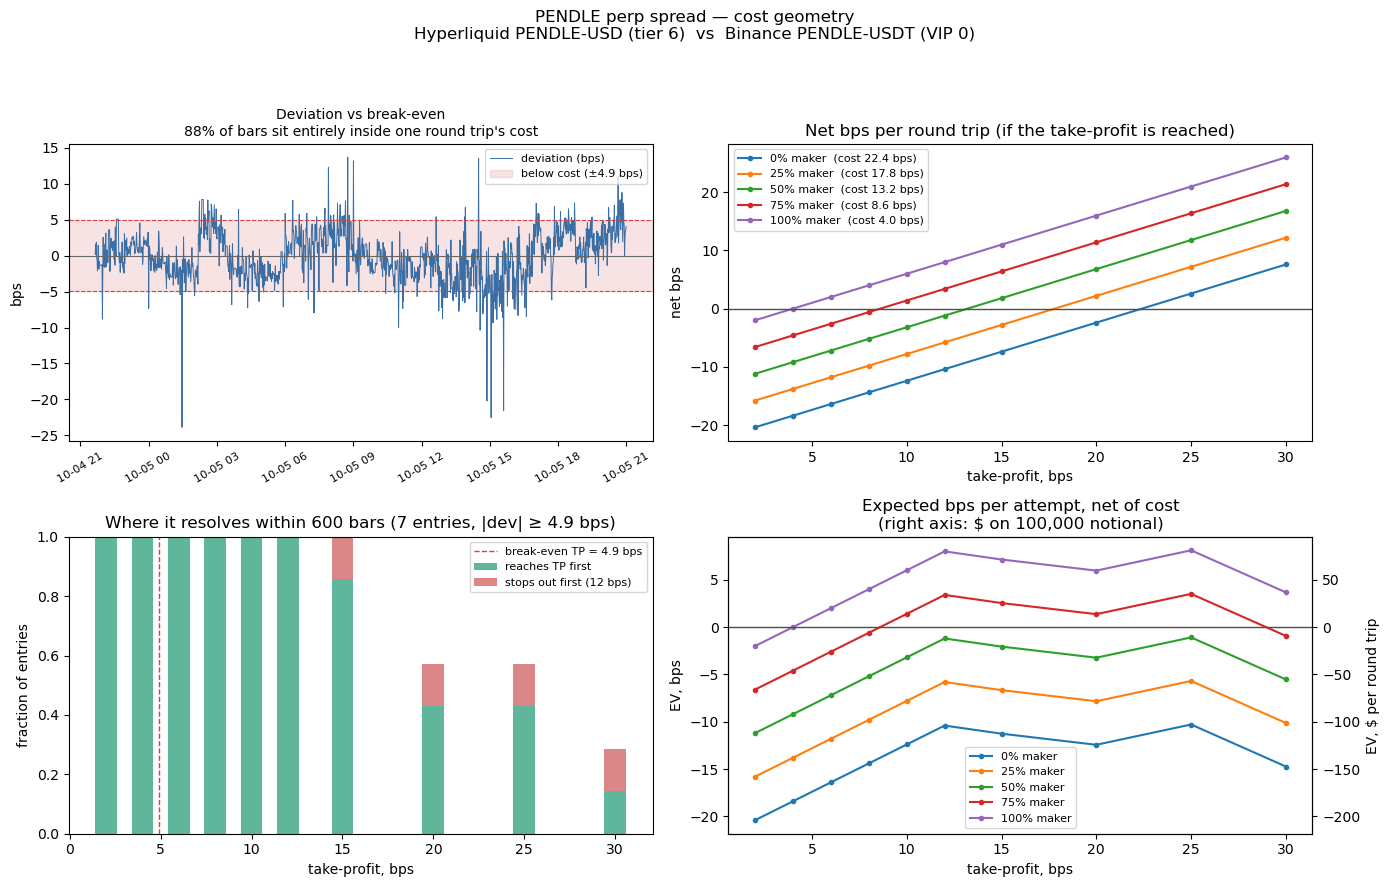

In [31]:
from spread_cost import plot_pnl, cost_breakdown

ref        = (df.hl_mid + df.bin_mid) / 2
spread_bps = (df.hl_mid - df.bin_mid) / ref * 1e4

fig, res = plot_pnl(spread_bps[-2_000:], taker=0.05, maker=0.95,
                    stop_bps=12, horizon_bars=600)   # 600 bars = 60s at 100ms

In [8]:
df.head()

,bin_mid,bin_bid,ask,bid_size_bin,ask_size_bin,imbalance_bin,microprice_bin,hl_mid,hl_bid,bid_size_hl,ask_size_hl,imbalance_hl,microprice_hl,microprice_diff,mid_diff,reference_mid,mid_diff_bps
datetime,,,,,,,,,,,,,,,,,
2026-09-29 03:16:00+00:00,86.2415,86.241,86.242,62.57,44.03,0.173921,86.241587,86.2475,86.247,2.25,175.92,-0.974743,86.247013,0.005426,0.0060,86.24450,0.695697
2026-09-29 03:17:00+00:00,86.3175,86.317,86.318,32.95,73.79,-0.382612,86.317309,86.3430,86.338,3.05,4.63,-0.205729,86.341971,0.024663,0.0255,86.33025,2.953773
2026-09-29 03:18:00+00:00,86.3035,86.303,86.304,141.78,1.01,0.985853,86.303993,86.2965,86.296,146.59,107.44,0.154116,86.296577,-0.007416,-0.0070,86.30000,-0.811124
2026-09-29 03:19:00+00:00,86.4245,86.424,86.425,33.54,25.10,0.143929,86.424572,86.4625,86.462,0.13,722.38,-0.999640,86.462000,0.037428,0.0380,86.44350,4.395935
2026-09-29 03:20:00+00:00,86.5165,86.516,86.517,30.00,41.20,-0.157303,86.516421,86.5175,86.517,243.10,494.08,-0.340460,86.517330,0.000908,0.0010,86.51700,0.115584


## Markov-Switching Latent Fair-Value Model

Start with the observed price decomposition:

$$
p_t = m_t + s_t + \epsilon_t
$$

where:

- $p_t$ = observed market price
- $m_t$ = latent efficient / fair price
- $s_t$ = temporary, predictable microstructure distortion
- $\epsilon_t$ = residual observation noise

### Efficient-price process

Model the latent efficient price as a random walk:

$$
m_t = m_{t-1} + \eta_t
$$

where $\eta_t$ represents innovations to the true efficient price.

### Microstructure distortion

Let the temporary distortion depend on both its previous value and current market-microstructure information:

$$
s_t
=
\rho_{z_t}s_{t-1}
+
\beta_{z_t}^{\top}x_t
+
\nu_t
$$

where:

- $z_t$ = latent market regime
- $\rho_{z_t}$ = persistence of temporary price distortion in regime $z_t$
- $\beta_{z_t}$ = regime-dependent weights on market-microstructure variables
- $x_t$ = vector of observable order-book / order-flow features
- $\nu_t$ = innovation to the temporary distortion

A simple initial feature vector could be:

$$
x_t =
\begin{bmatrix}
\text{microprice} - \text{midprice} \\
\text{order-flow imbalance} \\
\text{trade imbalance} \\
\text{bid-ask spread} \\
\text{depth imbalance}
\end{bmatrix}
$$

### Markov regime process

Assume the latent regime follows a Markov process:

$$
z_t \sim \operatorname{Markov}(P)
$$

where:

$$
P_{ij}
=
P(z_t = j \mid z_{t-1} = i)
$$

Possible regimes may correspond to states such as:

1. Balanced / normal market
2. Sustained buy pressure
3. Sustained sell pressure
4. Low-liquidity / stressed market

The regimes do not necessarily need to be manually labelled beforehand; they can be inferred statistically and interpreted afterwards.

### Fair-value estimate

The model produces an estimate of the current temporary distortion:

$$
\hat{s}_t
=
E[s_t \mid \mathcal{F}_t]
$$

and therefore the estimated latent efficient price is:

$$
\boxed{
\hat{m}_t = p_t - \hat{s}_t
}
$$

The purpose of the model is therefore to use observable microstructure information to separate temporary price pressure from movements in the underlying efficient price.

### Research progression

A natural progression for the research is:

1. **Midprice benchmark**
2. **Microprice benchmark**
3. **Linear microstructure fair-value model**
4. **Regime-dependent / Markov model**
5. **Full Markov-switching state-space model**

Each increase in complexity should only be retained if it improves out-of-sample estimates of the latent fair price or subsequent price movement.

In [12]:
pip install importlib

  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
  Created wheel for importlib: filename=importlib-1.0.4-py3-none-any.whl size=5936 sha256=3e568fc39791f8d14a66bc39ea62d1a03a7e69b309143839f6935ff00fcd2ed5
  Stored in directory: c:\users\markp\appdata\local\pip\cache\wheels\03\4a\6e\7c4a313549653a504574fa29f907139c752051ef05210df605
Successfully built importlib
Note: you may need to restart the kernel to use updated packages.


In [20]:
import importlib
import numpy as np
import matplotlib.pyplot as plt

In [21]:
import fv_models as fv
importlib.reload(fv)        # so edits to the module take effect
 
f = fv.build_features(df, basis_window=120, vol_window=60)
print(f.shape)
f.tail(3)

(9585, 14)


,spread,basis,y,mp_hl,mp_bin,mp_adj,imb_hl,imb_bin,imb_diff,spr_hl,spr_bin,dep_hl,dep_bin,vol
datetime,,,,,,,,,,,,,,
2026-10-05 20:57:00+00:00,3.056299,2.203018,0.853281,0.042983,0.046359,-0.003377,0.815691,0.87977,-0.064078,0.105390,0.105390,8.377333,4.793888,2.712050
2026-10-05 20:58:00+00:00,3.165241,2.235671,0.929570,-0.002542,0.017956,-0.020498,-0.048195,0.34037,-0.388565,0.105508,0.105508,3.890391,4.571510,2.706877
2026-10-05 20:59:00+00:00,3.692645,2.254792,1.437853,0.050319,-0.013684,0.064003,0.953883,-0.25940,1.213283,0.105504,0.105504,8.317712,4.887714,2.609413


In [22]:
COST_BPS = 4.92             # from cost_breakdown() earlier in the notebook
 
_ = fv.magnitude_check(f, cost_bps=COST_BPS)

|y| median                  1.600
|y| 95th                    6.307
|mp_adj| median             0.041
|mp_adj| 95th               0.264
quoted spread HL median     0.113
quoted spread BIN median    0.112
round-trip cost             4.920

microprice adj (95th) as % of cost : 5.37%
bars                               : 9585
lag-1 autocorr of y                : 0.888
effective independent observations : 567


In [23]:
res_by_h = {}
for h in (5, 15, 30, 60):
    res_by_h[h] = fv.run_ladder(f, horizon=h, cost_bps=COST_BPS, n_splits=5)
    print(f"\n===== horizon = {h} bars =====")
    print(res_by_h[h]["table"].to_string())
 
HORIZON = 30                # pick one to inspect below
res = res_by_h[HORIZON]


===== horizon = 5 bars =====
              oos_r2      n    hit  mean_net  total_net
1_mid         -0.217  212.0  0.363    -0.365    -77.354
2_microprice  -0.217  213.0  0.366    -0.345    -73.516
3_linear      -0.202  211.0  0.365    -0.106    -22.340
4_markov      -0.425  278.0  0.403     0.165     45.893

===== horizon = 15 bars =====
              oos_r2      n    hit  mean_net  total_net
1_mid          0.080  258.0  0.554     5.204   1342.510
2_microprice   0.080  257.0  0.549     5.181   1331.421
3_linear       0.073  295.0  0.529     4.445   1311.197
4_markov       0.004  371.0  0.536     3.579   1327.970

===== horizon = 30 bars =====
              oos_r2      n    hit  mean_net  total_net
1_mid          0.350  420.0  0.664     8.794   3693.361
2_microprice   0.350  418.0  0.663     8.803   3679.591
3_linear       0.328  692.0  0.503     4.554   3151.630
4_markov       0.377  697.0  0.504     4.549   3170.747

===== horizon = 60 bars =====
              oos_r2       n    hit  

In [24]:
# %% ------------------------------------------------------------------
# CELL 4 - your two actual questions
#
# "both"            trades the incumbent and the model both take
# "incumbent only"  trades the model SKIPS -> if mean_net here is negative,
#                   the moving fair value is avoiding toxic fills
# "<model> only"    trades the model ADDS  -> if mean_net here is positive,
#                   it is finding inefficiency the static rule misses
#
# Either column can be the win. Skipping bad trades and adding good ones
# are different edges and you should not average them together.
# ---------------------------------------------------------------------
print("best rung:", res["best"], "   horizon:", res["horizon"], "bars")
print()
print(res["overlap"].to_string())

best rung: 2_microprice    horizon: 30 bars

                       n  mean_net
both               416.0     8.838
incumbent only       4.0     4.197
2_microprice only    2.0     1.510


In [25]:
# %% ------------------------------------------------------------------
# CELL 5 - is the regime real, or did the filter fit outliers?
#
# Run this BEFORE believing cell 3. On simulated data with one true regime
# the Markov rung still produces numbers, and these checks are what catch
# it: one state collapses onto a few outliers, giving a sigma ratio of 30
# or 700 and an occupancy of 0.3%.
# ---------------------------------------------------------------------
fv.regime_health(res)
print()
print(fv.regime_summary(res["par"]).to_string())
print()
print(fv.name_the_regime(res).to_string())

PASS  sigma ratio in [1.5, 6]    2.39
PASS  all rho in (0, 1)          [0.686, 0.308]
PASS  min occupancy >= 10%       [0.768, 0.232]
FAIL  min duration >= 5 bars     [14.1, 4.5]

At least one tell failed: treat the Markov rung's result as an artefact and stop at rung 3.

         rho (pullback)  half-life (bars)  sigma (bps/bar)  stay prob  expected duration (bars)
state 0           0.686             1.838            1.400      0.929                    14.108
state 1           0.308             0.589            3.346      0.777                     4.487

         low state  high state  ratio  time in state
vol          2.474       3.989  1.612          0.232
spr_hl       0.199       0.267  1.344            NaN
spr_bin      0.113       0.116  1.022            NaN
dep_hl       5.302       5.234  0.987            NaN
dep_bin      5.142       5.022  0.977            NaN
y           -0.054       0.273 -5.012            NaN


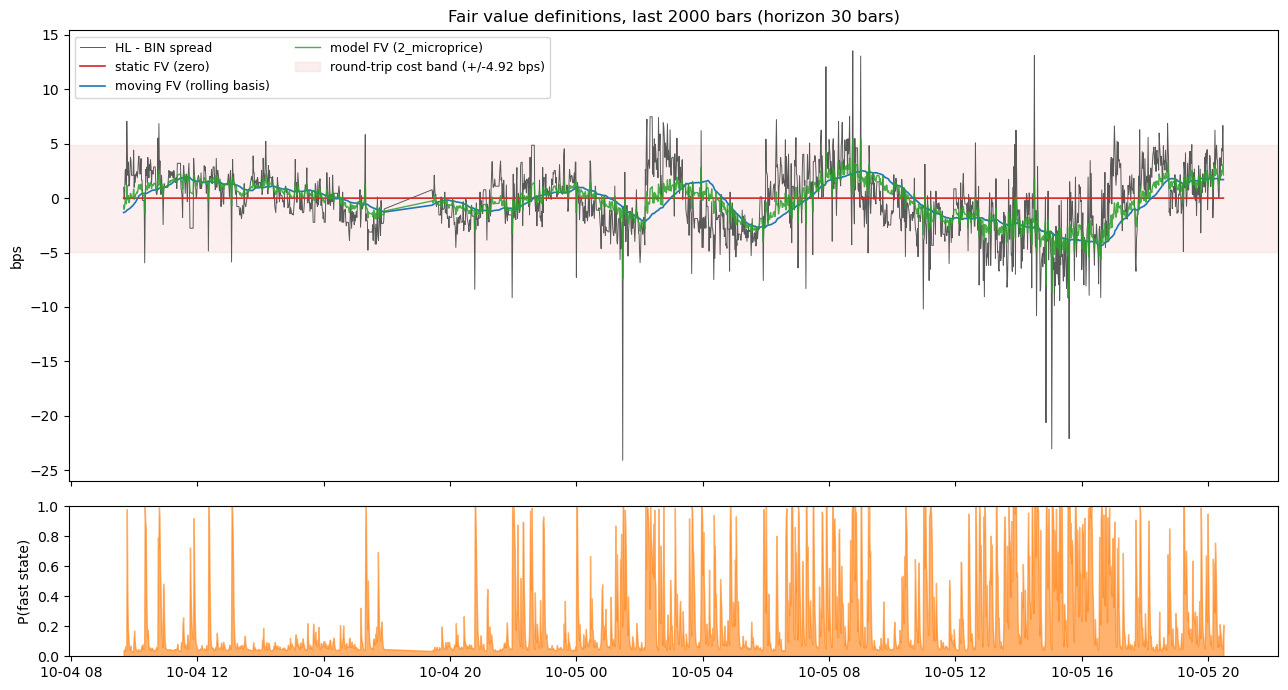

In [26]:
# %% ------------------------------------------------------------------
# CELL 6 - the picture: static vs moving fair value
# ---------------------------------------------------------------------
fvf = fv.fv_frame(f, res).dropna()
tail = fvf.iloc[-2000:]
p_hi = res["probs"].reindex(tail.index).iloc[:, -1]
 
fig, ax = plt.subplots(2, 1, figsize=(13, 7), sharex=True,
                       gridspec_kw={"height_ratios": [3, 1]})
 
ax[0].plot(tail.index, tail["spread"], lw=0.7, color="0.35",
           label="HL - BIN spread")
ax[0].plot(tail.index, tail["fv_static"], lw=1.2, color="tab:red",
           label="static FV (zero)")
ax[0].plot(tail.index, tail["fv_moving"], lw=1.2, color="tab:blue",
           label=f"moving FV (rolling basis)")
ax[0].plot(tail.index, tail["fv_model"], lw=1.0, color="tab:green",
           alpha=0.85, label=f"model FV ({res['best']})")
ax[0].axhspan(-COST_BPS, COST_BPS, color="tab:red", alpha=0.07,
              label=f"round-trip cost band (+/-{COST_BPS:.2f} bps)")
ax[0].set_ylabel("bps")
ax[0].legend(ncol=2, fontsize=9)
ax[0].set_title(f"Fair value definitions, last {len(tail)} bars "
                f"(horizon {res['horizon']} bars)")
 
ax[1].fill_between(tail.index, 0, p_hi, color="tab:orange", alpha=0.6)
ax[1].set_ylim(0, 1)
ax[1].set_ylabel("P(fast state)")
ax[1].set_xlabel("")
plt.tight_layout()
plt.show()


######## FV definition: static ########
Hyperliquid PENDLE-USD (tier 6): fees                        0.24
Hyperliquid PENDLE-USD (tier 6): half-spread (taker legs)    0.18
Binance PENDLE-USDT (VIP 0): fees                            4.30
Binance PENDLE-USDT (VIP 0): half-spread (taker legs)        0.20
TOTAL round-trip cost                                        4.92

break-even move  : 4.92 bps  (= 49 USD per 100,000 notional)
deviation |x| >= cost : 11.1% of bars
best TP in grid  : 12 bps  EV +7.08 bps  hit 100%

######## FV definition: moving ########
Hyperliquid PENDLE-USD (tier 6): fees                        0.24
Hyperliquid PENDLE-USD (tier 6): half-spread (taker legs)    0.18
Binance PENDLE-USDT (VIP 0): fees                            4.30
Binance PENDLE-USDT (VIP 0): half-spread (taker legs)        0.20
TOTAL round-trip cost                                        4.92

break-even move  : 4.92 bps  (= 49 USD per 100,000 notional)
deviation |x| >= cost : 9.8% of bars
best TP i

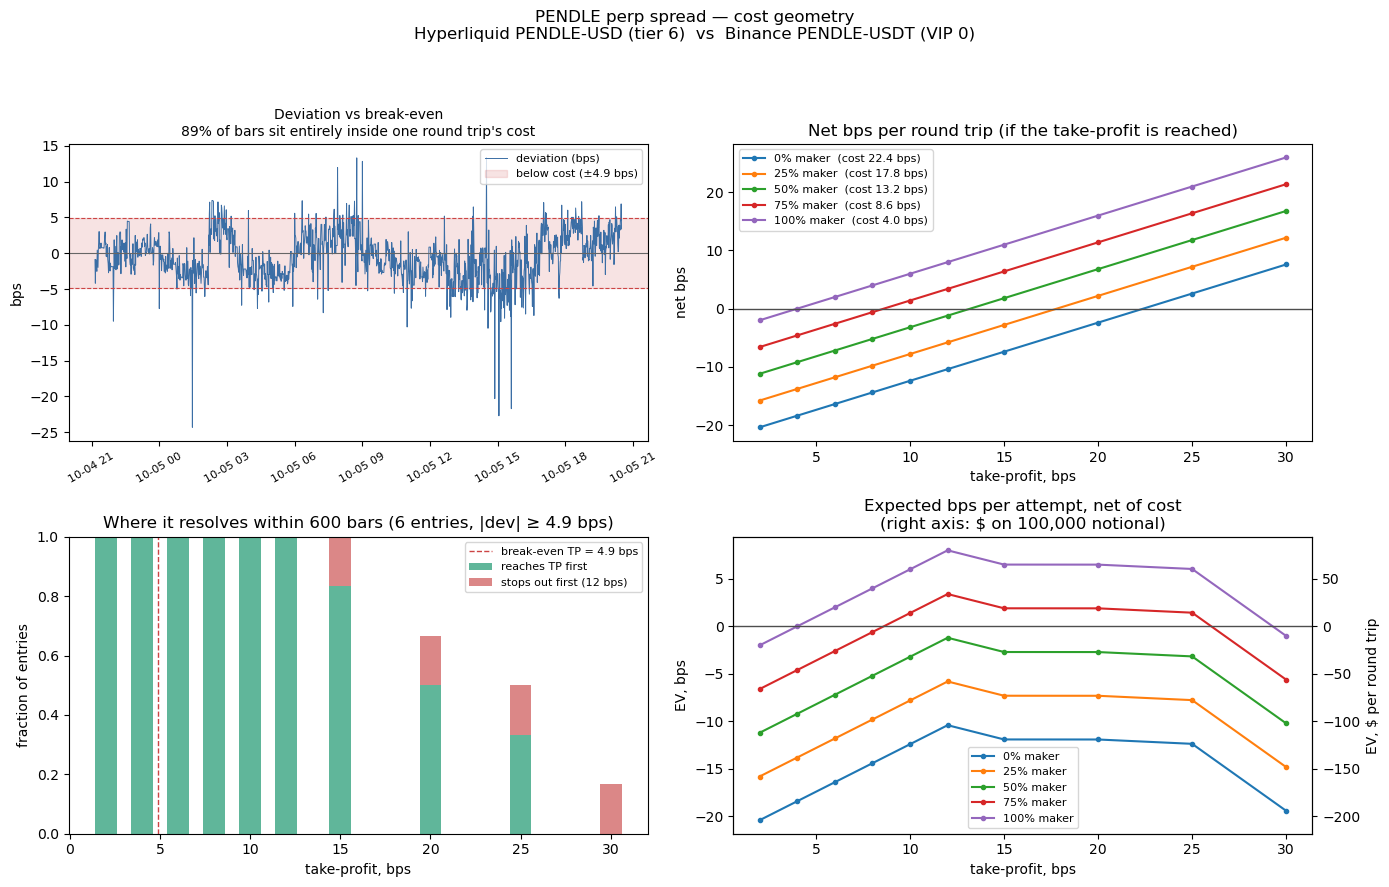

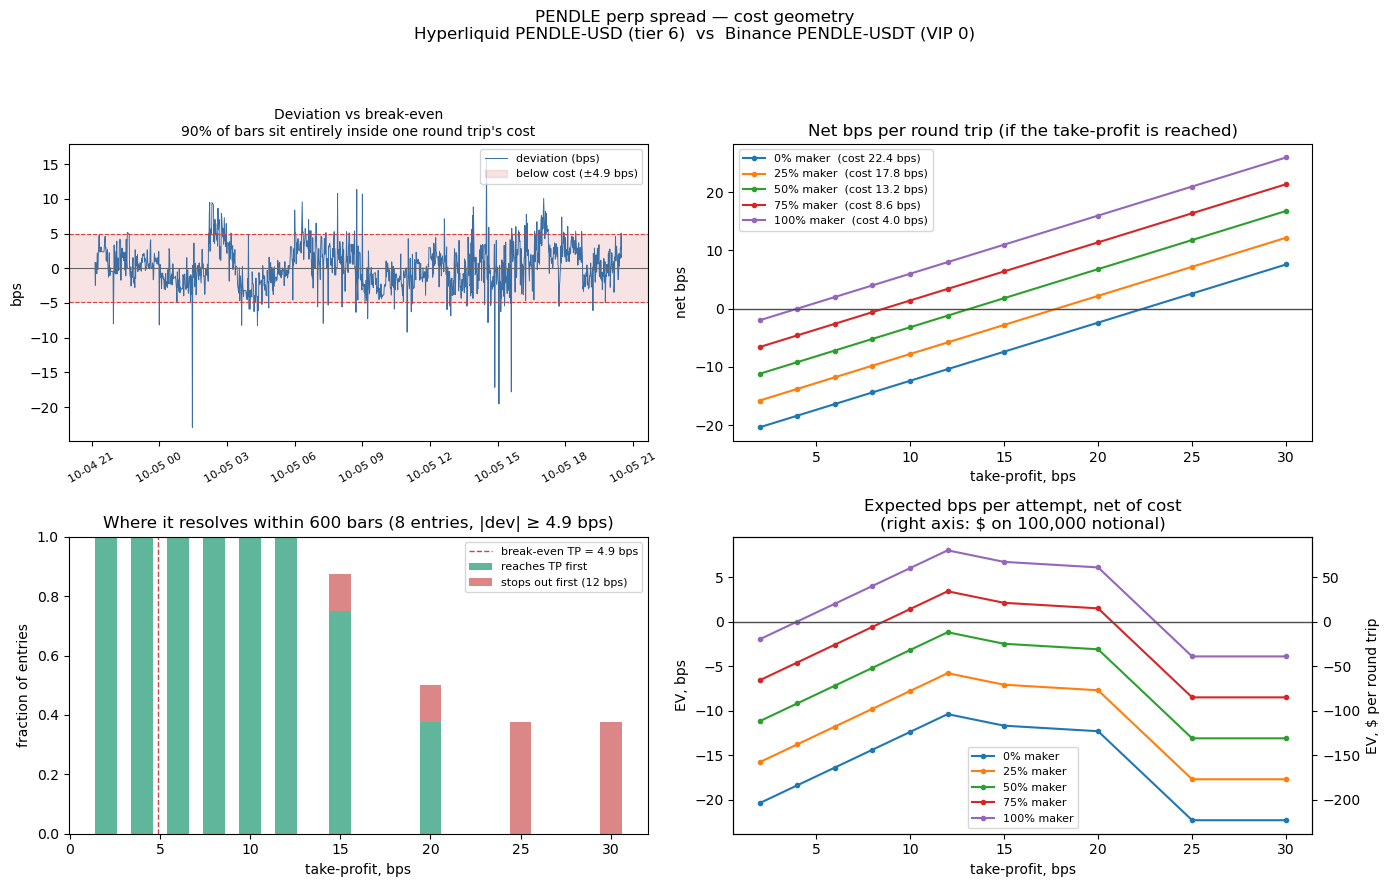

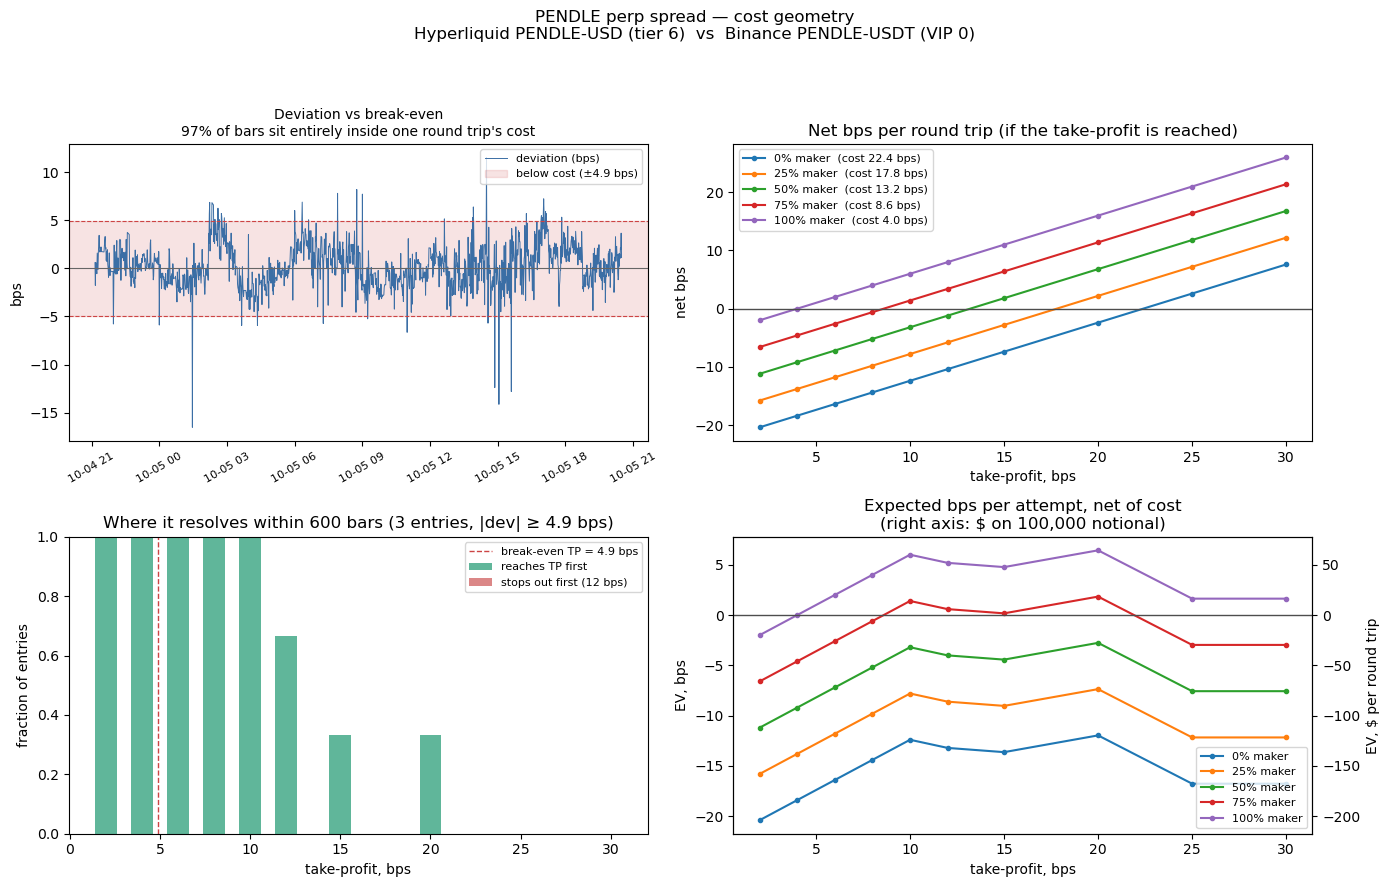

In [27]:
from spread_cost import plot_pnl
 
dev = fv.deviation_series(f, res).dropna()
 
for name in ("static", "moving", "model"):
    print(f"\n######## FV definition: {name} ########")
    plot_pnl(dev[name].iloc[-2_000:], taker=0.05, maker=0.95,
             stop_bps=12, horizon_bars=600)

In [28]:
# %% ------------------------------------------------------------------
# CELL 8 - the honesty check: how much of this is sample size?
#
# magnitude_check printed effective independent observations. Compare the
# difference in mean_net between rungs against its own standard error. If
# the gap is inside one standard error you have measured nothing.
# ---------------------------------------------------------------------
t = res["table"]
n_eff = len(f) * (1 - f["y"].autocorr(1)) / (1 + f["y"].autocorr(1))
for rung in t.index:
    if t.loc[rung, "n"] and np.isfinite(t.loc[rung, "mean_net"]):
        n_tr = t.loc[rung, "n"]
        # trades overlap at horizon h, so deflate the trade count too
        n_ind = max(n_tr / max(res["horizon"], 1), 1)
        se = np.nanstd(res["data"]["d"]) / np.sqrt(n_ind)
        print(f"{rung:<14} mean_net {t.loc[rung,'mean_net']:+.3f}  "
              f"se ~{se:.3f}  ({n_ind:.0f} independent trades)")
print(f"\neffective independent bars in sample: {n_eff:.0f} of {len(f)}")

1_mid          mean_net +8.794  se ~2.261  (14 independent trades)
2_microprice   mean_net +8.803  se ~2.266  (14 independent trades)
3_linear       mean_net +4.554  se ~1.761  (23 independent trades)
4_markov       mean_net +4.549  se ~1.755  (23 independent trades)

effective independent bars in sample: 567 of 9585
